# Chapter 5: Eager and Lazy APIs

In [1]:
import polars as pl
pl.__version__  # The book is built with Polars version 1.20.0
import polars.selectors as cs

## Eager API: DataFrame

In [10]:
%%time
trips = pl.read_parquet("data/taxi/yellow_tripdata_*.parquet", )  
sum_per_vendor = trips.group_by("VendorID").agg(
    cs.numeric().exclude('VendorID').sum()
)

income_per_distance_per_vendor = sum_per_vendor.select(
    "VendorID",
    income_per_distance=pl.col("total_amount") / pl.col("trip_distance"),
)

top_three = income_per_distance_per_vendor.sort(  
    by="income_per_distance", descending=True
).head(3)

top_three

CPU times: total: 14.2 s
Wall time: 3.44 s


VendorID,income_per_distance
i64,f64
1,6.434789
6,5.296493
5,4.731557


## Lazy API: LazyFrame

In [ ]:
# This raises a SchemaError:
# names_lf = pl.LazyFrame({"name": ["Alice", "Bob", "Charlie"], "age": [25, 30, 35]})

# erroneous_query = names_lf.with_columns(
#     sliced_age=pl.col("age").str.slice(1, 3)
# )

# result_df = erroneous_query.collect()

## Performance Differences

In [11]:
%%time
trips = pl.scan_parquet("data/taxi/yellow_tripdata_*.parquet")
sum_per_vendor = trips.group_by("VendorID").agg(
    cs.numeric().exclude('VendorID').sum()
)

income_per_distance_per_vendor = sum_per_vendor.select(
    "VendorID",
    income_per_distance=pl.col("total_amount") / pl.col("trip_distance"),
)

top_three = income_per_distance_per_vendor.sort(
    by="income_per_distance", descending=True
).head(3)

top_three.collect()

CPU times: total: 2.3 s
Wall time: 856 ms


VendorID,income_per_distance
i64,f64
1,6.434789
6,5.296493
5,4.731557


In [13]:
lf = pl.LazyFrame({"col1": [1, 2, 3], "col2": [4, 5, 6]})

# ... Some heavy computation ...

print(lf.collect())

print(lf.with_columns(pl.col("col1") + 1).collect())  

shape: (3, 2)
┌──────┬──────┐
│ col1 ┆ col2 │
│ ---  ┆ ---  │
│ i64  ┆ i64  │
╞══════╪══════╡
│ 1    ┆ 4    │
│ 2    ┆ 5    │
│ 3    ┆ 6    │
└──────┴──────┘
shape: (3, 2)
┌──────┬──────┐
│ col1 ┆ col2 │
│ ---  ┆ ---  │
│ i64  ┆ i64  │
╞══════╪══════╡
│ 2    ┆ 4    │
│ 3    ┆ 5    │
│ 4    ┆ 6    │
└──────┴──────┘


In [5]:
import polars as pl
from pathlib import Path
from datetime import datetime

min_dir = Path('D:/SFData/parquet/stocks/stock_mins')

In [2]:
day_data.estimated_size('mb')

56.126980781555176

In [3]:
day_data.select(
    pl.len().alias("rows"),
    pl.col("trade_time").min().alias("min_time"),
    pl.col("trade_time").max().alias("max_time"),
)

rows,min_time,max_time
u32,datetime[μs],datetime[μs]
905437,2020-01-15 09:30:00,2020-01-15 15:00:00


In [10]:
query2 = (
    pl.scan_parquet(min_dir / '**/*.parquet', hive_partitioning=True)
    .filter(
        # pl.col('year') == 2020,
        # pl.col('month') == 1,
        pl.col('trade_time').dt.date() == datetime(2020, 1, 17).date()
    )
    .select(
        'stk_code',
        'trade_time',
        'close',
        'open',
        'high',
        'low',
        'vol',
        'amount',
    )
)

print(query2.explain(optimized=True, engine='streaming'))
# day_data2 = query2.collect(engine='streaming')

Parquet SCAN [D:/SFData/parquet/stocks/stock_mins/year=2009/month=1/part-000.parquet, ... 240 other sources]
PROJECT 8/15 COLUMNS
SELECTION: (col("trade_time").dt.date() == 2020-01-17)
ESTIMATED ROWS: 3648143615


In [8]:
print(query.explain(optimized=True, engine='streaming'))

Parquet SCAN [D:/SFData/parquet/stocks/stock_mins/year=2009/month=1/part-000.parquet, ... 240 other sources]
PROJECT 8/13 COLUMNS
SELECTION: (col("trade_time") >= 2020-01-15 00:00:00) & (col("trade_time") < 2020-01-16 00:00:00)
ESTIMATED ROWS: 3648143615


In [6]:
day_data2.estimated_size('mb')

56.126980781555176

In [3]:
# 对比同一天、相同列的三种筛选方式；日期转换查询可能耗时数分钟。
from datetime import datetime, timedelta
from pathlib import Path
from time import perf_counter

import polars as pl
from polars.testing import assert_frame_equal

compare_start = datetime(2020, 1, 15)
compare_end = compare_start + timedelta(days=1)
compare_dir = Path('D:/SFData/parquet/stocks/stock_mins')
show_scan_logs = False  # 改为 True 查看读取器的执行日志。
compare_columns = [
    'stk_code', 'trade_time', 'close', 'open',
    'high', 'low', 'vol', 'amount',
]

# 统一开启 Hive 解析，确保仅比较筛选条件的差异。
compare_base = pl.scan_parquet(
    compare_dir / '**/*.parquet', hive_partitioning=True
)
date_filter = (
    pl.col('trade_time').dt.date() == compare_start.date()
)
compare_queries = {
    '时间范围': compare_base.filter(
        pl.col('trade_time') >= compare_start,
        pl.col('trade_time') < compare_end,
    ).select(compare_columns),
    # '日期转换': compare_base.filter(date_filter).select(compare_columns),
    'Hive 分区 + 日期转换': compare_base.filter(
        pl.col('year') == compare_start.year,
        pl.col('month') == compare_start.month,
        date_filter,
    ).select(compare_columns),
    'Hive 分区 + 时间范围': compare_base.filter(
            pl.col('year') == compare_start.year,
            pl.col('month') == compare_start.month,
            pl.col('trade_time') >= compare_start,
            pl.col('trade_time') < compare_end,
        ).select(compare_columns),
}

compare_records = []
reference_result = None
# 日志状态在结束或中断时自动恢复；日志本身也可能影响计时。
with pl.Config(verbose=show_scan_logs):
    for name, lazy_query in compare_queries.items():
        print(f'开始：{name}', flush=True)
        started = perf_counter()
        current_result = lazy_query.collect(engine='streaming')
        elapsed = perf_counter() - started
        print(f'完成：{elapsed:.3f} 秒', flush=True)

        # 排序及一致性校验不计入查询耗时，忽略执行器输出顺序。
        current_result = current_result.sort(compare_columns)
        if reference_result is None:
            reference_result = current_result
        else:
            assert_frame_equal(reference_result, current_result)
        compare_records.append({
            '查询方式': name,
            '耗时_秒': elapsed,
            '行数': current_result.height,
            '最早时间': current_result['trade_time'].min(),
            '最晚时间': current_result['trade_time'].max(),
        })
        del current_result

print('结果一致。单轮耗时受磁盘缓存和执行顺序影响。')
compare_summary = pl.DataFrame(compare_records)
del reference_result
compare_summary


开始：时间范围
完成：0.245 秒
开始：Hive 分区 + 日期转换
完成：0.130 秒
开始：Hive 分区 + 时间范围
完成：0.136 秒
结果一致。单轮耗时受磁盘缓存和执行顺序影响。


查询方式,耗时_秒,行数,最早时间,最晚时间
str,f64,i64,datetime[μs],datetime[μs]
"""时间范围""",0.2453,905437,2020-01-15 09:30:00,2020-01-15 15:00:00
"""Hive 分区 + 日期转换""",0.130243,905437,2020-01-15 09:30:00,2020-01-15 15:00:00
"""Hive 分区 + 时间范围""",0.136063,905437,2020-01-15 09:30:00,2020-01-15 15:00:00


In [6]:
from pathlib import Path

import pyarrow.parquet as pq

file_path = next(
    (
        min_dir / "year=2020" / "month=1"
    ).glob("*.parquet")
)

parquet_file = pq.ParquetFile(file_path)
metadata = parquet_file.metadata

print("文件：", file_path)
print("行数：", metadata.num_rows)
print("列数：", metadata.num_columns)
print("Row group 数量：", metadata.num_row_groups)
print("写入程序：", metadata.created_by)
print(parquet_file.schema)

文件： D:\SFData\parquet\stocks\stock_mins\year=2020\month=1\part-000.parquet
行数： 14482895
列数： 13
Row group 数量： 221
写入程序： parquet-cpp-arrow version 19.0.0
required group field_id=-1 schema {
  optional binary field_id=-1 stk_code (String);
  optional int64 field_id=-1 trade_time (Timestamp(isAdjustedToUTC=false, timeUnit=microseconds, is_from_converted_type=false, force_set_converted_type=false));
  optional double field_id=-1 close;
  optional double field_id=-1 open;
  optional double field_id=-1 high;
  optional double field_id=-1 low;
  optional double field_id=-1 vol;
  optional double field_id=-1 amount;
  optional double field_id=-1 adj_factor;
  optional double field_id=-1 adj_open;
  optional double field_id=-1 adj_high;
  optional double field_id=-1 adj_low;
  optional double field_id=-1 adj_close;
}



In [ ]:
import polars as pl

time_column_index = metadata.schema.names.index("trade_time")
records = []

for index in range(metadata.num_row_groups):
    row_group = metadata.row_group(index)
    column = row_group.column(time_column_index)
    statistics = column.statistics

    has_min_max = (
        statistics is not None and statistics.has_min_max
    )

    records.append(
        {
            "row_group": index,
            "rows": row_group.num_rows,
            "min_time": statistics.min if has_min_max else None,
            "max_time": statistics.max if has_min_max else None,
            "null_count": (
                statistics.null_count
                if statistics is not None
                else None
            ),
            "compression": column.compression,
            "compressed_bytes": column.total_compressed_size,
        }
    )

pl.DataFrame(records)

row_group,rows,min_time,max_time,null_count,compression,compressed_bytes
i64,i64,datetime[μs],datetime[μs],i64,str,i64
0,65536,2020-01-02 09:30:00,2020-01-23 15:00:00,0,"""ZSTD""",30871
1,65536,2020-01-02 09:30:00,2020-01-23 15:00:00,0,"""ZSTD""",29332
2,65536,2020-01-02 09:30:00,2020-01-23 15:00:00,0,"""ZSTD""",29331
3,65536,2020-01-02 09:30:00,2020-01-23 15:00:00,0,"""ZSTD""",29332
4,65536,2020-01-02 09:30:00,2020-01-23 15:00:00,0,"""ZSTD""",29331
…,…,…,…,…,…,…
216,65536,2020-01-02 09:30:00,2020-01-23 15:00:00,0,"""ZSTD""",26533
217,65536,2020-01-02 09:30:00,2020-01-23 15:00:00,0,"""ZSTD""",26515
218,65536,2020-01-02 09:30:00,2020-01-23 15:00:00,0,"""ZSTD""",33178


In [8]:
metadata.row_group(0).to_dict()

{'num_columns': 13,
 'num_rows': 65536,
 'total_byte_size': 1751773,
 'columns': [{'file_offset': 0,
   'file_path': '',
   'physical_type': 'BYTE_ARRAY',
   'num_values': 65536,
   'path_in_schema': 'stk_code',
   'is_stats_set': True,
   'statistics': {'has_min_max': True,
    'min': '000001.SZ',
    'max': '000021.SZ',
    'null_count': 0,
    'distinct_count': None,
    'num_values': 65536,
    'physical_type': 'BYTE_ARRAY'},
   'geo_statistics': None,
   'compression': 'ZSTD',
   'encodings': ('PLAIN', 'RLE', 'RLE_DICTIONARY'),
   'has_dictionary_page': True,
   'dictionary_page_offset': 4,
   'data_page_offset': 98,
   'total_compressed_size': 212,
   'total_uncompressed_size': 359,
   'bloom_filter_offset': None,
   'bloom_filter_length': None},
  {'file_offset': 0,
   'file_path': '',
   'physical_type': 'INT64',
   'num_values': 65536,
   'path_in_schema': 'trade_time',
   'is_stats_set': True,
   'statistics': {'has_min_max': True,
    'min': datetime.datetime(2020, 1, 2, 9, 

In [9]:
code_index = metadata.schema.names.index("stk_code")
records = []

for index in range(metadata.num_row_groups):
    row_group = metadata.row_group(index)
    statistics = row_group.column(code_index).statistics
    has_min_max = (
        statistics is not None and statistics.has_min_max
    )

    records.append(
        {
            "row_group": index,
            "min_code": statistics.min if has_min_max else None,
            "max_code": statistics.max if has_min_max else None,
        }
    )

pl.DataFrame(records)

row_group,min_code,max_code
i64,str,str
0,"""000001.SZ""","""000021.SZ"""
1,"""000021.SZ""","""000042.SZ"""
2,"""000042.SZ""","""000069.SZ"""
3,"""000069.SZ""","""000166.SZ"""
4,"""000166.SZ""","""000417.SZ"""
…,…,…
216,"""603987.SH""","""688007.SH"""
217,"""688007.SH""","""688030.SH"""
218,"""688030.SH""","""688116.SH"""


In [16]:
from pathlib import Path

import polars as pl

min_dir = Path(r"D:\SFData\parquet\stocks\stock_mins")

# 替换成实际代码，格式和类型必须与 stk_code 列一致。
stock_code = "000002.SZ"

query = (
    pl.scan_parquet(
        min_dir / "**/*.parquet",
        hive_partitioning=True,
    )
    .filter(pl.col("stk_code") == stock_code)
    .select(
        "stk_code",
        "trade_time",
        "open",
        "high",
        "low",
        "close",
        "vol",
        "amount",
    )
    # .sort("trade_time")
)

stock_data = query.collect(engine="streaming")

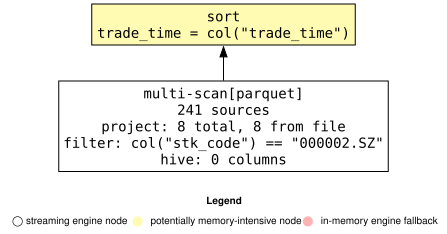

In [14]:
query.show_graph(engine="streaming")

In [18]:
stock_data.height

1040156

In [24]:
from pathlib import Path

import duckdb

min_dir = Path(r"D:\SFData\parquet\stocks\stock_mins")
parquet_pattern = (min_dir / "**/*.parquet").as_posix()
stock_code = "000002.SZ"

with duckdb.connect() as con:
    stock_data = con.execute(
        """
        SELECT
            stk_code,
            trade_time,
            open,
            high,
            low,
            close,
            vol,
            amount
        FROM read_parquet(?, hive_partitioning = false)
        WHERE stk_code = ?
        ORDER BY trade_time
        """,
        [parquet_pattern, stock_code],
    ).pl()

In [25]:
stock_data.head()

stk_code,trade_time,open,high,low,close,vol,amount
str,datetime[μs],f64,f64,f64,f64,f64,f64
"""000002.SZ""",2009-01-05 09:30:00,6.58,6.58,6.58,6.58,408100.0,2.685298e6
"""000002.SZ""",2009-01-05 09:31:00,6.55,6.57,6.53,6.55,953700.0,6.267931e6
"""000002.SZ""",2009-01-05 09:32:00,6.55,6.55,6.53,6.53,342500.0,2.24217e6
"""000002.SZ""",2009-01-05 09:33:00,6.52,6.54,6.51,6.54,337000.0,2.198461e6
"""000002.SZ""",2009-01-05 09:34:00,6.53,6.55,6.53,6.55,328220.0,2.147756e6


In [26]:
import gc
import platform
from datetime import datetime, timedelta
from pathlib import Path
from time import perf_counter

import duckdb
import polars as pl
from polars.testing import assert_frame_equal


# 修改这里的路径、股票代码、查询日期和重复次数。
DATA_DIR = Path(r"D:\SFData\parquet\stocks\stock_mins")
STOCK_CODE = "000002.SZ"
DAY_START = datetime(2020, 1, 15)
REPEATS = 6

DAY_END = DAY_START + timedelta(days=1)
MONTH_START = DAY_START.replace(day=1)
MONTH_END = (
    MONTH_START.replace(year=MONTH_START.year + 1, month=1)
    if MONTH_START.month == 12
    else MONTH_START.replace(month=MONTH_START.month + 1)
)

COLUMNS = [
    "stk_code",
    "trade_time",
    "open",
    "high",
    "low",
    "close",
    "vol",
    "amount",
]

# 固定文件集合，排除两边通配符枚举方式的差异。
# 文件枚举不计时；扫描初始化、规划、执行和结果生成均计时。
FILES = sorted(
    path.as_posix()
    for path in DATA_DIR.rglob("*.parquet")
)
if not FILES:
    raise FileNotFoundError(f"没有找到 Parquet 文件：{DATA_DIR}")

# Polars 线程池通常已初始化，让 DuckDB 使用相同线程数。
THREADS = pl.thread_pool_size()

print(
    f"Python={platform.python_version()}, "
    f"Polars={pl.__version__}, DuckDB={duckdb.__version__}"
)
print(f"文件数={len(FILES)}, 每个引擎线程数={THREADS}")

COLUMN_SQL = ", ".join(f'"{name}"' for name in COLUMNS)


def build_polars_query(case):
    """构造对应场景的 Polars 查询。"""
    query = pl.scan_parquet(FILES, hive_partitioning=True)

    if case == "单票全历史":
        return (
            query.filter(pl.col("stk_code") == STOCK_CODE)
            .select(COLUMNS)
            .sort("trade_time")
        )

    # 以下查询都在一个月以内，显式限制年月分区。
    query = query.filter(
        pl.col("year") == DAY_START.year,
        pl.col("month") == DAY_START.month,
    )

    if case == "单票一个月":
        return (
            query.filter(
                pl.col("stk_code") == STOCK_CODE,
                pl.col("trade_time") >= MONTH_START,
                pl.col("trade_time") < MONTH_END,
            )
            .select(COLUMNS)
            .sort("trade_time")
        )

    query = query.filter(
        pl.col("trade_time") >= DAY_START,
        pl.col("trade_time") < DAY_END,
    )

    if case == "单日全市场":
        return query.select(COLUMNS).sort(
            ["stk_code", "trade_time"]
        )

    if case == "单日按股票聚合":
        # 显式转 Float64，统一两边 SUM 的输出类型。
        return (
            query.group_by("stk_code")
            .agg(
                pl.len().cast(pl.Int64).alias("rows"),
                pl.col("vol")
                .cast(pl.Float64)
                .sum()
                .alias("sum_vol"),
                pl.col("amount")
                .cast(pl.Float64)
                .sum()
                .alias("sum_amount"),
            )
            .sort("stk_code")
        )

    raise ValueError(f"未知场景：{case}")


def build_duckdb_query(case):
    """构造语义相同的 SQL 和参数。"""
    source = "read_parquet(?, hive_partitioning = true)"

    if case == "单票全历史":
        return (
            f"""
            SELECT {COLUMN_SQL}
            FROM {source}
            WHERE stk_code = ?
            ORDER BY trade_time
            """,
            [FILES, STOCK_CODE],
        )

    partition_sql = '"year" = ? AND "month" = ?'
    partition_params = [
        FILES,
        DAY_START.year,
        DAY_START.month,
    ]

    if case == "单票一个月":
        return (
            f"""
            SELECT {COLUMN_SQL}
            FROM {source}
            WHERE {partition_sql}
              AND stk_code = ?
              AND trade_time >= ?
              AND trade_time < ?
            ORDER BY trade_time
            """,
            partition_params
            + [STOCK_CODE, MONTH_START, MONTH_END],
        )

    if case == "单日全市场":
        return (
            f"""
            SELECT {COLUMN_SQL}
            FROM {source}
            WHERE {partition_sql}
              AND trade_time >= ?
              AND trade_time < ?
            ORDER BY stk_code, trade_time
            """,
            partition_params + [DAY_START, DAY_END],
        )

    if case == "单日按股票聚合":
        return (
            f"""
            SELECT
                stk_code,
                COUNT(*) AS rows,
                COALESCE(
                    SUM(CAST(vol AS DOUBLE)), 0.0
                ) AS sum_vol,
                COALESCE(
                    SUM(CAST(amount AS DOUBLE)), 0.0
                ) AS sum_amount
            FROM {source}
            WHERE {partition_sql}
              AND trade_time >= ?
              AND trade_time < ?
            GROUP BY stk_code
            ORDER BY stk_code
            """,
            partition_params + [DAY_START, DAY_END],
        )

    raise ValueError(f"未知场景：{case}")


def run_once(connection, engine, case):
    """计时查询构造、执行及生成 Polars DataFrame。"""
    gc.collect()

    started = perf_counter()
    if engine == "Polars":
        result = build_polars_query(case).collect(
            engine="streaming"
        )
    else:
        sql, parameters = build_duckdb_query(case)
        result = connection.execute(sql, parameters).pl()
    elapsed = perf_counter() - started

    return result, elapsed


def check_results(left, right, case):
    """在计时之外校验结果，容许浮点聚合的微小误差。"""
    if left.height == 0 or right.height == 0:
        raise ValueError(
            f"{case} 返回空结果，请检查股票代码和日期"
        )

    # 不要求物理 dtype 完全一致；聚合容许浮点求和顺序差异。
    # 排序消除相同时间戳下可能存在的输出顺序差异。
    keys = left.columns
    assert_frame_equal(
        left.sort(keys),
        right.sort(keys),
        check_dtypes=False,
        check_exact=case != "单日按股票聚合",
        rel_tol=1e-8,
        abs_tol=1e-6,
    )


CASES = [
    "单票全历史",
    "单日全市场",
    "单票一个月",
    "单日按股票聚合",
]

records = []

# 复用同一个连接，连接初始化不计入查询耗时。
with duckdb.connect() as connection:
    connection.execute(f"SET threads = {THREADS}")

    for case_index, case in enumerate(CASES):
        print(f"\n开始：{case}", flush=True)

        # 首次执行单独记录，同时作为预热和正确性校验。
        # 不清除系统文件缓存，因此不能称为冷缓存测试。
        first_order = (
            ["Polars", "DuckDB"]
            if case_index % 2 == 0
            else ["DuckDB", "Polars"]
        )
        first_results = {}

        for engine in first_order:
            result, elapsed = run_once(
                connection, engine, case
            )
            first_results[engine] = result
            records.append(
                {
                    "场景": case,
                    "引擎": engine,
                    "阶段": "首次",
                    "轮次": 0,
                    "秒": elapsed,
                    "行数": result.height,
                }
            )
            print(
                f"  首次 {engine}: {elapsed:.3f} 秒，"
                f"{result.height:,} 行",
                flush=True,
            )
            del result

        check_results(
            first_results["Polars"],
            first_results["DuckDB"],
            case,
        )
        del first_results
        print("  结果一致", flush=True)

        # 每轮交换执行顺序，降低先后顺序造成的偏差。
        for repeat in range(REPEATS):
            order = (
                ["Polars", "DuckDB"]
                if (repeat + case_index) % 2 == 0
                else ["DuckDB", "Polars"]
            )

            for engine in order:
                result, elapsed = run_once(
                    connection, engine, case
                )
                records.append(
                    {
                        "场景": case,
                        "引擎": engine,
                        "阶段": "重复",
                        "轮次": repeat + 1,
                        "秒": elapsed,
                        "行数": result.height,
                    }
                )
                print(
                    f"  第 {repeat + 1} 轮 {engine}: "
                    f"{elapsed:.3f} 秒",
                    flush=True,
                )
                del result


benchmark_detail = pl.DataFrame(records)

benchmark_first = benchmark_detail.filter(
    pl.col("阶段") == "首次"
).select("场景", "引擎", "秒", "行数")

benchmark_summary = (
    benchmark_detail.filter(pl.col("阶段") == "重复")
    .group_by("场景", "引擎")
    .agg(
        pl.col("秒").median().alias("中位数_秒"),
        pl.col("秒").min().alias("最快_秒"),
        pl.col("秒").max().alias("最慢_秒"),
        pl.col("行数").first(),
    )
    .sort("场景", "引擎")
)

benchmark_ratio = (
    benchmark_summary.filter(pl.col("引擎") == "Polars")
    .select(
        "场景",
        pl.col("中位数_秒").alias("Polars_秒"),
    )
    .join(
        benchmark_summary.filter(
            pl.col("引擎") == "DuckDB"
        ).select(
            "场景",
            pl.col("中位数_秒").alias("DuckDB_秒"),
        ),
        on="场景",
    )
    .with_columns(
        (
            pl.col("DuckDB_秒") / pl.col("Polars_秒")
        ).alias("DuckDB耗时/Polars耗时")
    )
    .sort("场景")
)

print("\n首次执行（不代表冷缓存）：")
display(benchmark_first)

print("\n重复执行统计：")
display(benchmark_summary)

print("\n中位数耗时对比：比值 > 1 表示 Polars 更快")
display(benchmark_ratio)

Python=3.14.8, Polars=2.0.0, DuckDB=1.5.6
文件数=241, 每个引擎线程数=12

开始：单票全历史
  首次 Polars: 0.312 秒，1,040,156 行
  首次 DuckDB: 0.992 秒，1,040,156 行
  结果一致
  第 1 轮 Polars: 0.233 秒
  第 1 轮 DuckDB: 0.998 秒
  第 2 轮 DuckDB: 1.055 秒
  第 2 轮 Polars: 0.279 秒
  第 3 轮 Polars: 0.271 秒
  第 3 轮 DuckDB: 1.096 秒
  第 4 轮 DuckDB: 1.082 秒
  第 4 轮 Polars: 0.264 秒
  第 5 轮 Polars: 0.286 秒
  第 5 轮 DuckDB: 1.098 秒
  第 6 轮 DuckDB: 1.007 秒
  第 6 轮 Polars: 0.251 秒

开始：单日全市场
  首次 DuckDB: 0.318 秒，905,437 行
  首次 Polars: 0.405 秒，905,437 行
  结果一致
  第 1 轮 DuckDB: 0.302 秒
  第 1 轮 Polars: 0.192 秒
  第 2 轮 Polars: 0.205 秒
  第 2 轮 DuckDB: 0.339 秒
  第 3 轮 DuckDB: 0.300 秒
  第 3 轮 Polars: 0.194 秒
  第 4 轮 Polars: 0.191 秒
  第 4 轮 DuckDB: 0.285 秒
  第 5 轮 DuckDB: 0.324 秒
  第 5 轮 Polars: 0.193 秒
  第 6 轮 Polars: 0.173 秒
  第 6 轮 DuckDB: 0.301 秒

开始：单票一个月
  首次 Polars: 0.107 秒，3,856 行
  首次 DuckDB: 0.031 秒，3,856 行
  结果一致
  第 1 轮 Polars: 0.040 秒
  第 1 轮 DuckDB: 0.032 秒
  第 2 轮 DuckDB: 0.031 秒
  第 2 轮 Polars: 0.043 秒
  第 3 轮 Polars: 0.028 秒
  第 3

场景,引擎,秒,行数
str,str,f64,i64
"""单票全历史""","""Polars""",0.312019,1040156
"""单票全历史""","""DuckDB""",0.991577,1040156
"""单日全市场""","""DuckDB""",0.318321,905437
"""单日全市场""","""Polars""",0.405264,905437
"""单票一个月""","""Polars""",0.106921,3856
"""单票一个月""","""DuckDB""",0.030999,3856
"""单日按股票聚合""","""DuckDB""",0.302696,3757
"""单日按股票聚合""","""Polars""",0.525064,3757



重复执行统计：


场景,引擎,中位数_秒,最快_秒,最慢_秒,行数
str,str,f64,f64,f64,i64
"""单日全市场""","""DuckDB""",0.301183,0.285196,0.338634,905437
"""单日全市场""","""Polars""",0.192428,0.173133,0.205305,905437
"""单日按股票聚合""","""DuckDB""",0.118936,0.108175,0.154153,3757
"""单日按股票聚合""","""Polars""",0.096455,0.094535,0.104469,3757
"""单票一个月""","""DuckDB""",0.031121,0.030379,0.031749,3856
"""单票一个月""","""Polars""",0.027765,0.026855,0.04271,3856
"""单票全历史""","""DuckDB""",1.068688,0.997516,1.097573,1040156
"""单票全历史""","""Polars""",0.267242,0.232727,0.286476,1040156



中位数耗时对比：比值 > 1 表示 Polars 更快


场景,Polars_秒,DuckDB_秒,DuckDB耗时/Polars耗时
str,f64,f64,f64
"""单日全市场""",0.192428,0.301183,1.565175
"""单日按股票聚合""",0.096455,0.118936,1.233071
"""单票一个月""",0.027765,0.031121,1.120857
"""单票全历史""",0.267242,1.068688,3.998955


In [27]:
import gc
from datetime import datetime
from pathlib import Path
from time import perf_counter

import duckdb
import polars as pl
from IPython.display import display
from polars.testing import assert_frame_equal


# 可修改为同一个月内的多日区间，结束时间不包含在查询内。
DATA_DIR = Path(r"D:\SFData\parquet\stocks\stock_mins")
START = datetime(2026, 10, 13)
END = datetime(2026, 10, 16)
REPEATS = 6

if END <= START:
    raise ValueError("END 必须晚于 START")

FILES = sorted(
    path.as_posix()
    for path in DATA_DIR.rglob("*.parquet")
)
if not FILES:
    raise FileNotFoundError(f"没有找到 Parquet 文件：{DATA_DIR}")

THREADS = pl.thread_pool_size()
COLUMNS = [
    "stk_code",
    "trade_time",
    "open",
    "high",
    "low",
    "close",
    "vol",
    "amount",
]

print(
    f"Polars={pl.__version__}, DuckDB={duckdb.__version__}, "
    f"线程数={THREADS}, 文件数={len(FILES)}"
)
print(f"查询区间：[{START}, {END})")


def polars_base():
    """先限制原始时间范围，再生成查询需要的辅助列。"""
    return (
        pl.scan_parquet(FILES, hive_partitioning=False)
        .filter(
            pl.col("trade_time") >= START,
            pl.col("trade_time") < END,
        )
        .select(COLUMNS)
        .with_columns(
            pl.col("trade_time").dt.date().alias("trade_date")
        )
    )


def build_polars(case):
    """构造三个场景的原生 Polars 查询。"""
    base = polars_base()
    daily_keys = ["trade_date", "stk_code"]

    if case == "1_每日成交额前10名的分钟行情":
        top_stocks = (
            base.group_by(daily_keys)
            .agg(
                pl.col("amount")
                .cast(pl.Float64)
                .sum()
                .alias("daily_amount")
            )
            .sort(
                ["trade_date", "daily_amount", "stk_code"],
                descending=[False, True, False],
            )
            .group_by("trade_date", maintain_order=True)
            .head(10)
            .select(daily_keys)
        )

        return (
            base.join(top_stocks, on=daily_keys, how="semi")
            .select(COLUMNS)
            .sort(["stk_code", "trade_time"])
        )

    if case == "2_每票每日成交量最大的3根K线":
        return (
            base.sort(
                ["stk_code", "trade_date", "vol", "trade_time"],
                descending=[False, False, True, False],
                nulls_last=True,
            )
            .group_by(daily_keys, maintain_order=True)
            .head(3)
            .select(COLUMNS)
            .sort(["stk_code", "trade_time"])
        )

    if case == "4_每票每日分时段成交额":
        minute = (
            pl.col("trade_time").dt.hour().cast(pl.Int32) * 60
            + pl.col("trade_time").dt.minute().cast(pl.Int32)
        )
        opening = (minute >= 570) & (minute < 600)
        closing = (minute >= 870) & (minute <= 900)
        amount = pl.col("amount").cast(pl.Float64)

        return (
            base.group_by(daily_keys)
            .agg(
                amount.sum().alias("total_amount"),
                amount.filter(opening).sum().alias(
                    "opening_amount"
                ),
                amount.filter(closing).sum().alias(
                    "closing_amount"
                ),
            )
            .sort(daily_keys)
        )

    raise ValueError(f"未知场景：{case}")


COLUMN_SQL = ", ".join(f'"{name}"' for name in COLUMNS)

# NOT MATERIALIZED 允许优化器内联此公共表达式。
# 各引擎如何复用中间结果，由各自优化器决定。
BASE_SQL = f"""
WITH base AS NOT MATERIALIZED (
    SELECT
        {COLUMN_SQL},
        CAST(trade_time AS DATE) AS trade_date
    FROM read_parquet(?, hive_partitioning = false)
    WHERE trade_time >= ? AND trade_time < ?
)
"""

SQL_QUERIES = {
    "1_每日成交额前10名的分钟行情": BASE_SQL + f"""
        , daily AS (
            SELECT
                trade_date,
                stk_code,
                COALESCE(
                    SUM(CAST(amount AS DOUBLE)), 0.0
                ) AS daily_amount
            FROM base
            GROUP BY trade_date, stk_code
        ),
        top_stocks AS (
            SELECT trade_date, stk_code
            FROM daily
            QUALIFY ROW_NUMBER() OVER (
                PARTITION BY trade_date
                ORDER BY daily_amount DESC, stk_code
            ) <= 10
        )
        SELECT {", ".join(f'b."{c}"' for c in COLUMNS)}
        FROM base AS b
        SEMI JOIN top_stocks AS t
            ON b.trade_date = t.trade_date
            AND b.stk_code = t.stk_code
        ORDER BY b.stk_code, b.trade_time
    """,
    "2_每票每日成交量最大的3根K线": BASE_SQL + f"""
        SELECT {COLUMN_SQL}
        FROM base
        QUALIFY ROW_NUMBER() OVER (
            PARTITION BY trade_date, stk_code
            ORDER BY vol DESC NULLS LAST, trade_time
        ) <= 3
        ORDER BY stk_code, trade_time
    """,
    "4_每票每日分时段成交额": BASE_SQL + """
        SELECT
            trade_date,
            stk_code,
            COALESCE(
                SUM(CAST(amount AS DOUBLE)), 0.0
            ) AS total_amount,
            COALESCE(
                SUM(CAST(amount AS DOUBLE)) FILTER (
                    WHERE CAST(trade_time AS TIME) >= TIME '09:30:00'
                      AND CAST(trade_time AS TIME) < TIME '10:00:00'
                ), 0.0
            ) AS opening_amount,
            COALESCE(
                SUM(CAST(amount AS DOUBLE)) FILTER (
                    WHERE CAST(trade_time AS TIME) >= TIME '14:30:00'
                      AND CAST(trade_time AS TIME) <= TIME '15:00:00'
                ), 0.0
            ) AS closing_amount
        FROM base
        GROUP BY trade_date, stk_code
        ORDER BY trade_date, stk_code
    """,
}


def run_once(connection, engine, case):
    """计时查询规划、执行、排序和生成 Polars DataFrame。"""
    gc.collect()

    started = perf_counter()
    if engine == "Polars":
        result = build_polars(case).collect(
            engine="streaming"
        )
    else:
        result = connection.execute(
            SQL_QUERIES[case],
            [FILES, START, END],
        ).pl()

    elapsed = perf_counter() - started
    return result, elapsed


def check_results(left, right, case):
    """在计时外比较结果，允许浮点聚合的微小误差。"""
    if left.is_empty() or right.is_empty():
        raise ValueError(f"{case} 返回空结果，请检查日期")

    assert_frame_equal(
        left.sort(left.columns),
        right.sort(right.columns),
        check_dtypes=False,
        check_exact=case.startswith("2_"),
        rel_tol=1e-8,
        abs_tol=1e-6,
    )


records = []

with duckdb.connect() as connection:
    connection.execute(f"SET threads = {THREADS}")

    for case_index, case in enumerate(SQL_QUERIES):
        print(f"\n开始：{case}", flush=True)

        first_results = {}
        first_order = (
            ["Polars", "DuckDB"]
            if case_index % 2 == 0
            else ["DuckDB", "Polars"]
        )

        # 首次执行同时用于预热和结果校验，不代表冷缓存。
        for engine in first_order:
            result, elapsed = run_once(
                connection, engine, case
            )
            first_results[engine] = result
            records.append(
                {
                    "场景": case,
                    "引擎": engine,
                    "阶段": "首次",
                    "轮次": 0,
                    "秒": elapsed,
                    "行数": result.height,
                }
            )
            print(
                f"  首次 {engine}: {elapsed:.3f} 秒，"
                f"{result.height:,} 行",
                flush=True,
            )
            del result

        check_results(
            first_results["Polars"],
            first_results["DuckDB"],
            case,
        )
        del first_results
        print("  结果一致", flush=True)

        for repeat in range(REPEATS):
            order = (
                ["Polars", "DuckDB"]
                if (repeat + case_index) % 2 == 0
                else ["DuckDB", "Polars"]
            )

            for engine in order:
                result, elapsed = run_once(
                    connection, engine, case
                )
                records.append(
                    {
                        "场景": case,
                        "引擎": engine,
                        "阶段": "重复",
                        "轮次": repeat + 1,
                        "秒": elapsed,
                        "行数": result.height,
                    }
                )
                print(
                    f"  第 {repeat + 1} 轮 {engine}: "
                    f"{elapsed:.3f} 秒",
                    flush=True,
                )
                del result


benchmark_detail = pl.DataFrame(records)

benchmark_summary = (
    benchmark_detail.filter(pl.col("阶段") == "重复")
    .group_by("场景", "引擎")
    .agg(
        pl.col("秒").median().alias("中位数_秒"),
        pl.col("秒").min().alias("最快_秒"),
        pl.col("秒").max().alias("最慢_秒"),
        pl.col("行数").first(),
    )
    .sort("场景", "引擎")
)

benchmark_ratio = (
    benchmark_summary.filter(pl.col("引擎") == "Polars")
    .select(
        "场景",
        pl.col("中位数_秒").alias("Polars_秒"),
    )
    .join(
        benchmark_summary.filter(
            pl.col("引擎") == "DuckDB"
        ).select(
            "场景",
            pl.col("中位数_秒").alias("DuckDB_秒"),
        ),
        on="场景",
    )
    .with_columns(
        (
            pl.col("DuckDB_秒") / pl.col("Polars_秒")
        ).alias("DuckDB耗时/Polars耗时")
    )
    .sort("场景")
)

print("\n首次执行记录：")
display(
    benchmark_detail.filter(pl.col("阶段") == "首次")
    .select("场景", "引擎", "秒", "行数")
)

print("\n重复执行统计：")
display(benchmark_summary)

print("\n中位数对比：比值 > 1 表示 Polars 更快")
display(benchmark_ratio)

Polars=2.0.0, DuckDB=1.5.6, 线程数=12, 文件数=241
查询区间：[2026-10-13 00:00:00, 2026-10-16 00:00:00)

开始：1_每日成交额前10名的分钟行情
  首次 Polars: 2.029 秒，7,230 行
  首次 DuckDB: 2.145 秒，7,230 行
  结果一致
  第 1 轮 Polars: 0.211 秒
  第 1 轮 DuckDB: 1.599 秒
  第 2 轮 DuckDB: 1.557 秒
  第 2 轮 Polars: 0.245 秒
  第 3 轮 Polars: 0.196 秒
  第 3 轮 DuckDB: 1.745 秒
  第 4 轮 DuckDB: 1.705 秒
  第 4 轮 Polars: 0.233 秒
  第 5 轮 Polars: 0.198 秒
  第 5 轮 DuckDB: 1.542 秒
  第 6 轮 DuckDB: 1.565 秒
  第 6 轮 Polars: 0.253 秒

开始：2_每票每日成交量最大的3根K线
  首次 DuckDB: 1.738 秒，50,067 行
  首次 Polars: 0.796 秒，50,067 行
  结果一致
  第 1 轮 DuckDB: 2.039 秒
  第 1 轮 Polars: 0.597 秒
  第 2 轮 Polars: 0.662 秒
  第 2 轮 DuckDB: 2.052 秒
  第 3 轮 DuckDB: 2.012 秒
  第 3 轮 Polars: 0.621 秒
  第 4 轮 Polars: 0.678 秒
  第 4 轮 DuckDB: 2.112 秒
  第 5 轮 DuckDB: 2.103 秒
  第 5 轮 Polars: 0.622 秒
  第 6 轮 Polars: 0.682 秒
  第 6 轮 DuckDB: 2.052 秒

开始：4_每票每日分时段成交额
  首次 Polars: 0.489 秒，16,689 行
  首次 DuckDB: 0.953 秒，16,689 行
  结果一致
  第 1 轮 Polars: 0.330 秒
  第 1 轮 DuckDB: 0.875 秒
  第 2 轮 DuckDB: 0.827 秒
  

场景,引擎,秒,行数
str,str,f64,i64
"""1_每日成交额前10名的分钟行情""","""Polars""",2.028699,7230
"""1_每日成交额前10名的分钟行情""","""DuckDB""",2.144939,7230
"""2_每票每日成交量最大的3根K线""","""DuckDB""",1.737592,50067
"""2_每票每日成交量最大的3根K线""","""Polars""",0.795908,50067
"""4_每票每日分时段成交额""","""Polars""",0.489227,16689
"""4_每票每日分时段成交额""","""DuckDB""",0.953341,16689



重复执行统计：


场景,引擎,中位数_秒,最快_秒,最慢_秒,行数
str,str,f64,f64,f64,i64
"""1_每日成交额前10名的分钟行情""","""DuckDB""",1.582146,1.542465,1.744507,7230
"""1_每日成交额前10名的分钟行情""","""Polars""",0.222173,0.19575,0.252697,7230
"""2_每票每日成交量最大的3根K线""","""DuckDB""",2.052235,2.012027,2.11203,50067
"""2_每票每日成交量最大的3根K线""","""Polars""",0.641953,0.597314,0.681637,50067
"""4_每票每日分时段成交额""","""DuckDB""",0.785672,0.765481,0.8754,16689
"""4_每票每日分时段成交额""","""Polars""",0.269975,0.227527,0.330206,16689



中位数对比：比值 > 1 表示 Polars 更快


场景,Polars_秒,DuckDB_秒,DuckDB耗时/Polars耗时
str,f64,f64,f64
"""1_每日成交额前10名的分钟行情""",0.222173,1.582146,7.121218
"""2_每票每日成交量最大的3根K线""",0.641953,2.052235,3.196864
"""4_每票每日分时段成交额""",0.269975,0.785672,2.910164


In [30]:
stock_data = stock_data.with_columns(
    pl.col('trade_time').set_sorted()
)

In [31]:
stock_data.flags

{'stk_code': {'SORTED_ASC': False, 'SORTED_DESC': False},
 'trade_time': {'SORTED_ASC': True, 'SORTED_DESC': False},
 'open': {'SORTED_ASC': False, 'SORTED_DESC': False},
 'high': {'SORTED_ASC': False, 'SORTED_DESC': False},
 'low': {'SORTED_ASC': False, 'SORTED_DESC': False},
 'close': {'SORTED_ASC': False, 'SORTED_DESC': False},
 'vol': {'SORTED_ASC': False, 'SORTED_DESC': False},
 'amount': {'SORTED_ASC': False, 'SORTED_DESC': False}}

In [32]:
%run ./compare_cb_stock_window.py

display(polars_result)
display(duckdb_result)

结果一致；时间标签包含 10:35 与 11:25。
[{'trade_date': datetime.date(2026, 10, 15), 'cb_code': '111024.SH', 'cb_name': '澳弘转债', 'stk_code': '605058.SH', 'stk_short_name': '澳弘电子', 'cb_daily_amount': 892374.4698, 'minute_rows': 51, 'unique_minutes': 51, 'first_time': datetime.datetime(2026, 10, 15, 10, 35), 'last_time': datetime.datetime(2026, 10, 15, 11, 25), 'highest_price': 70.49, 'lowest_price': 70.49, 'stock_window_amount': 17354638.0}]


trade_date,cb_code,cb_name,stk_code,stk_short_name,cb_daily_amount,minute_rows,unique_minutes,first_time,last_time,highest_price,lowest_price,stock_window_amount
date,str,str,str,str,f64,i64,i64,datetime[μs],datetime[μs],f64,f64,f64
2026-10-15,"""111024.SH""","""澳弘转债""","""605058.SH""","""澳弘电子""",892374.4698,51,51,2026-10-15 10:35:00,2026-10-15 11:25:00,70.49,70.49,1.7354638e7


trade_date,cb_code,cb_name,stk_code,stk_short_name,cb_daily_amount,minute_rows,unique_minutes,first_time,last_time,highest_price,lowest_price,stock_window_amount
date,str,str,str,str,f64,i64,i64,datetime[μs],datetime[μs],f64,f64,f64
2026-10-15,"""111024.SH""","""澳弘转债""","""605058.SH""","""澳弘电子""",892374.4698,51,51,2026-10-15 10:35:00,2026-10-15 11:25:00,70.49,70.49,1.7354638e7


In [33]:
stock_data = stock_data.with_columns(
    pl.col('trade_time').dt.year().alias('year'),
    pl.col('trade_time').dt.month().alias('month'),
)

In [34]:
stock_data.write_parquet('./data/000001/', compression='zstd', partition_by=['year', 'month'])

In [42]:
american_stocks = pl.read_csv('./data/stock/', try_parse_dates=True)

In [43]:
american_stocks.glimpse()

Rows: 18476
Columns: 8
$ symbol     <str> 'ASML', 'ASML', 'ASML', 'ASML', 'ASML', 'ASML', 'ASML', 'ASML', 'ASML', 'ASML'
$ date      <date> 1999-01-04, 1999-01-05, 1999-01-06, 1999-01-07, 1999-01-08, 1999-01-11, 1999-01-12, 1999-01-13, 1999-01-14, 1999-01-15
$ open       <f64> 11.765625, 11.859375, 14.25, 14.742188, 16.078125, 15.046875, 14.953125, 13.6875, 15.609375, 15.070313
$ high       <f64> 12.28125, 14.25, 17.601563, 17.8125, 16.289063, 15.515625, 15.234375, 16.007813, 15.796875, 16.40625
$ low        <f64> 11.765625, 11.71875, 14.203125, 14.53125, 15.023438, 14.671875, 14.753906, 13.640625, 14.976563, 15.046875
$ close      <f64> 12.140625, 13.96875, 16.875, 16.851563, 15.796875, 15.234375, 14.765625, 15.796875, 15.28125, 16.21875
$ adj close  <f64> 7.522523, 8.655257, 10.456018, 10.441495, 9.787995, 9.439458, 9.149015, 9.787995, 9.468504, 10.049394
$ volume     <i64> 1801867, 8241600, 16400267, 17722133, 10696000, 4037867, 1118400, 5788267, 4803733, 4847733



## Functionality Differences

### Attributes

### Aggregation Methods

### Computation Methods

### Descriptive Methods

### GroupBy Methods

### Exporting Methods

### Manipulation and Selection Methods

### Miscellaneous Methods

## Tips and Tricks

### Going from LazyFrame to DataFrame and Vice Versa

### Joining a DataFrame with a LazyFrame

In [ ]:
# # This raises a TypeError:
# big_sales_data = pl.LazyFrame(
#     {"sale_id": [101, 102, 103], "amount": [250, 150, 300]}
# )

# sales_metadata = pl.DataFrame(
#     {"sale_id": [101, 102, 103], "category": ["A", "B", "A"]}
# )

# big_sales_data.join(sales_metadata, on="sale_id").collect()

In [44]:
big_sales_data = pl.LazyFrame(
    {"sale_id": [101, 102, 103], "amount": [250, 150, 300]}
)

sales_metadata = pl.DataFrame(
    {"sale_id": [101, 102, 103], "category": ["A", "B", "A"]}
)

big_sales_data.join(sales_metadata.lazy(), on="sale_id").collect()

sale_id,amount,category
i64,i64,str
101,250,"""A"""
103,300,"""A"""
102,150,"""B"""


### Caching Intermittent Results

In [47]:
lf = pl.LazyFrame({"col1": [1, 2, 3], "col2": [4, 5, 6]})

# ... Some heavy computation ...

lf = lf.collect().lazy()  
print(lf.collect())

print(lf.with_columns(pl.col("col1") + 1).collect())  

shape: (3, 2)
┌──────┬──────┐
│ col1 ┆ col2 │
│ ---  ┆ ---  │
│ i64  ┆ i64  │
╞══════╪══════╡
│ 1    ┆ 4    │
│ 2    ┆ 5    │
│ 3    ┆ 6    │
└──────┴──────┘
shape: (3, 2)
┌──────┬──────┐
│ col1 ┆ col2 │
│ ---  ┆ ---  │
│ i64  ┆ i64  │
╞══════╪══════╡
│ 2    ┆ 4    │
│ 3    ┆ 5    │
│ 4    ┆ 6    │
└──────┴──────┘


## Takeaways